## Домашка 4

#### *«Вы видите, но не наблюдаете.» — Шерлок*

Эта домашка про мониторинг метрик и детекцию аномалий. За неё можно получить максимум 12 баллов. 

**Дедлайны**   
Жесткий дедлайн: 18.10.2026 23:59 по МСК. 

После жесткого дедлайна работы не принимаются. 

**Правила сдачи**   
Задание выполняется самостоятельно, списывания не допускаются. При обнаружении одинаковых работ балл за задание анулируется у всех студентов, вне зависимости от того, кто у кого списал.    

**Использование ИИ**
- Использование генеративных моделей для написания кода допустимо при следующих условиях: сгенерированный фрагмент прочитан, адаптирован под условие задачи и данные, вы способны объяснить каждую его строку. Решение, полученное путем передачи модели формулировки задания целиком и прямого копирования ответа в ячейку ноутбука без содержательной переработки, оценивается в 0 баллов за это задание.
- Ответы на текстовые вопросы (описание поведения графика, интерпретация метрики, формулировка гипотез и т.п.) должны быть написаны вами самостоятельно в markdown-ячейках. Использование генеративных моделей для ответа на текстовые вопросы приводит к аннулированию всей работы, а не отдельного задания: интерпретация результатов — главный проверяемый в курсе навык, передача ее ИИ лишает нас возможности оценить, насколько хорошо вы усвоили материал.
- Если генеративная модель использовалась при решении, в конце ноутбука в отдельной markdown-ячейке укажите: номера заданий, при работе над которыми она применялась, использованную модель (с версией) и текст промтов. При обоснованном подозрении на использование ИИ, не отраженное в этом разделе, работа аннулируется целиком независимо от того, к какой части заданий относится подозрение.

#### **Как сдать домашку?**
1. Создайте закрытый репозиторий в личном гитхаб аккаунте для нашего предмета. 
2. Пригласите в него своего ассистента — распределение по ассистентам и их гитхаб юзернеймы находятся в ведомости на листочке нашей дисциплины. Это можно сделать в настройках через раздел Collaborators and teams, уровень доступа ассистента должен быть Write.
3. Скачайте этот ноутбук и решите задания (локально или в Google Colab).
4. В репозитории предмета создайте ветку с номером ДЗ (например hw_4). В эту ветку запушьте .ipynb-файл с решением. Создайте pull request и добавьте в него ассистента как Reviewer. В этот же PR можете пушить сколько угодно изменений, будем смотреть на последнюю версию до наступления дедлайна.
5. Ссылку на PR продублируйте в форме сдачи (форма будет доступна на LMS Karpov Courses и в Телеграм-канале курса).

Пункты 1-2 проделываются один раз. Если вы прошли эти шаги при сдаче других домашек, повторять их не нужно, начинайте сразу с пункта 3. 

**Внимание**: Если вы работаете в Google Colab, также скачивайте .ipynb файл и публикуйте его в репозитории. Ссылки на Colab к сдаче не принимаются.


Все датасеты, с которыми предлагается работать в домашних заданиях, взяты из открытых источников или сгенерированы. Любые паттерны, найденные вне заданной канвы решения, являются случайными и не несут в себе смысла или инсайта.

[Данные](https://github.com/brezhnevaan/hse_product_metrics_course/releases/download/datasets_for_hw/hw_4_data.zip)

In [1]:
import pandas as pd
import numpy as np
from datetime import datetime
import matplotlib.pyplot as plt
from scipy.stats import t
from statsmodels.tsa.seasonal import STL
import math

### Warm up

#### 1. Сопоставьте метод детекции аномалий с контекстом применения — 2 балла

a) Онлайн-мониторинг   
b) Батч-анализ по историческим данным  

1. Правило 3σ.
2. Generalized ESD
3. Grubbs test
4. CUMSUM
5. EWMA
6. STL-разложение + Generalized ESD

# your answer is here
a) Онлайн-мониторинг - методы, которые работают по мере поступления данных, пересчет идет по каждой новой точке, не нужно обучение по всей истории

1,4,5

Правило 3σ - скользящее окно

CUMSUM - накопление отклонений рекуррентно

EWMA - экспоненциальное сглаживание, рекуррентная форма

b) Батч-анализ по историческим данным - методы, требующие всей выборки сразу для корректного подсчета статистики

2,3,6

Generalized ESD - итеративно удаляет выбросы, работает только на всей выборке

Grubbs test - частный случай ESD

STL-разложение + Generalized ESD - раскладывает весь ряд, потом анализ остатков целиком

### Case Study. Система мониторинга метрик для Ecom-приложения 🥪

**Легенда**  
Вы работаете продуктовым аналитиком в ecom-приложении доставки FMCG-товаров. Компания — развивающийся стартап, в котором еще не выстроена система мониторинга метрик.   

Вам поручили провести исследование подходов к детекции аномалий на исторических данных и выбрать методологии, которые будет применять ваша компания для онлайн-мониторинга и ретроспективного анализа.

In [2]:
df = pd.read_csv('hw_4_fmcg.csv')

In [3]:
df['date'] = pd.to_datetime(df['date'])

In [4]:
df.head()

,date,items_sold,gmv,avg_item_price
0,2023-01-01,2907,14944.41,5.140836
1,2023-01-02,3030,16065.13,5.302023
2,2023-01-03,3070,17170.30,5.592932
3,2023-01-04,2708,14367.19,5.305462
4,2023-01-05,3177,16918.53,5.325316


In [5]:
df = df.sort_values('date').reset_index(drop=True)

Описание данных:

- date — дата, на которую агрегированы данные
- items_sold — число проданных в день товаров
- gmv – GMV проданных в день товаров
- avg_item_price — средняя цена проданных в день товаров

#### 2. Правило 3σ — 2 балла

1) Реализуйте правило 3σ для каждой метрики:
- gmv;
- items_sold;
- avg_item_price.

Расчет производите на всем датасете. В этом пункте вы имитируете онлайн-мониторинг, поэтому проверка проводится для каждой даты, а границы контроля рассчитываются за последние 28 дней до самой даты. 

2) Постройте графики: метрика + границы контроля + выделенные аномалии.

*Советую обернуть правило для расчета 3σ в функцию, она пригодится на следующем шаге.*

**Внимание: Тут и в дальнейшем для визуализации и ответа на тестовые вопросы формы используйте только данные ЗА МАЙ.**

In [6]:
# your code is here
metrics = ['gmv', 'items_sold', 'avg_item_price']

def get_3_sigma_cl(df, metric, window=28, sigma=3):
    
    df = df.copy()
    df[f'{metric}_mean'] = df[metric].shift(1).rolling(window=window, min_periods=window).mean()
    df[f'{metric}_ssd'] = df[metric].shift(1).rolling(window=window, min_periods=window).std(ddof=1)

    df[f'{metric}_ucl'] = df[f'{metric}_mean'] + sigma*df[f'{metric}_ssd']
    df[f'{metric}_lcl'] = df[f'{metric}_mean'] - sigma*df[f'{metric}_ssd']

    df[f'is_anomaly_{metric}'] = (df[metric] < df[f'{metric}_lcl']) | (df[metric] > df[f'{metric}_ucl'])
    return df

In [7]:
def get_3sigma_vis(df, metric, date_col='date'):

    plt.figure(figsize=(14, 6))
    plt.plot(df[date_col], df[metric], marker='o', markersize=3, label=metric)
    plt.plot(df[date_col], df[f'{metric}_ucl'], linestyle='--', color='grey', label='UCL')
    plt.plot(df[date_col], df[f'{metric}_lcl'], linestyle='--', color='grey', label='LCL')

    anom = df[df[f'is_anomaly_{metric}']]
    plt.scatter(anom[date_col], anom[metric], color='red', s=60, zorder=5, label='аномалия')

    plt.title(f'Правило 3сигм: {metric}')
    plt.xlabel('дата')
    plt.ylabel(metric)
    plt.xticks(rotation=45)
    plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

In [8]:
# Считаю границы на всем датасете
df_3sigma = df.copy()
for m in metrics:
    df_3sigma = get_3_sigma_cl(df_3sigma, m, window=28, sigma=3)

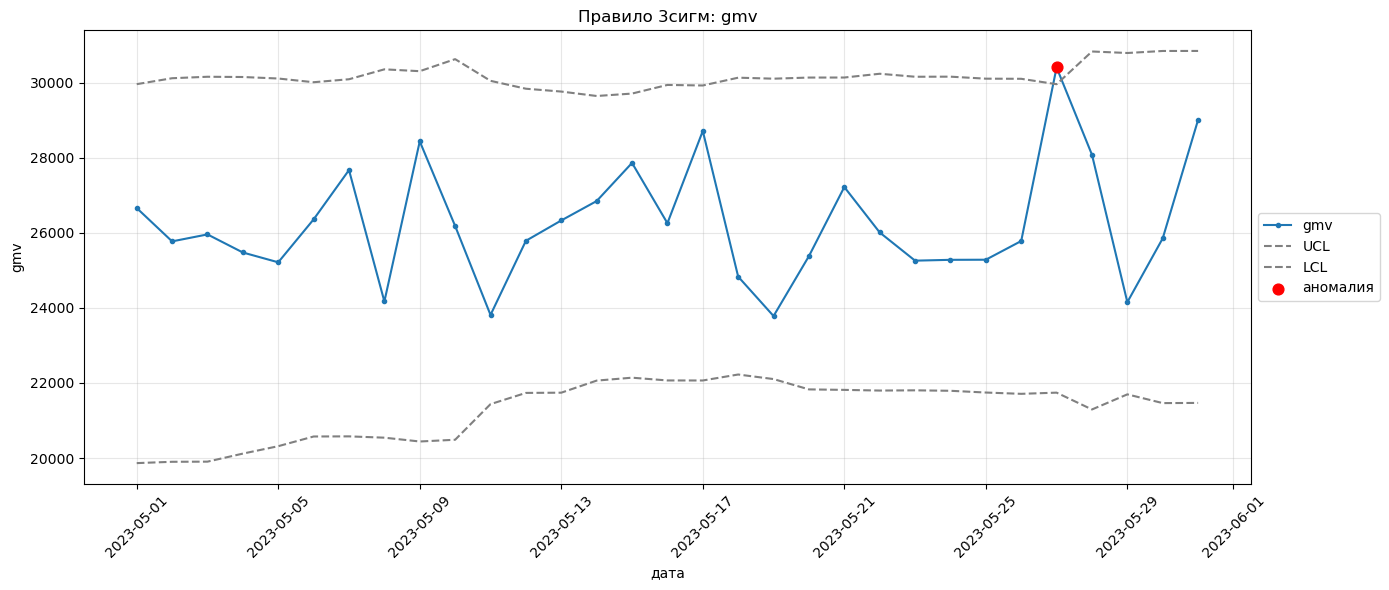

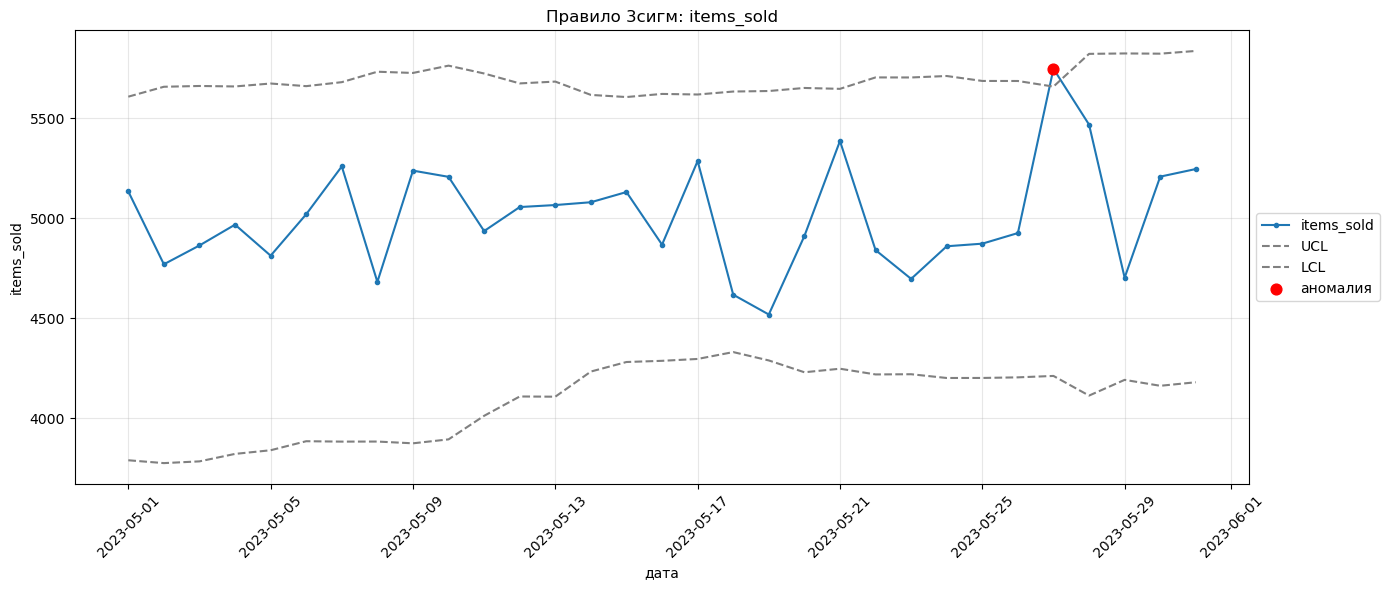

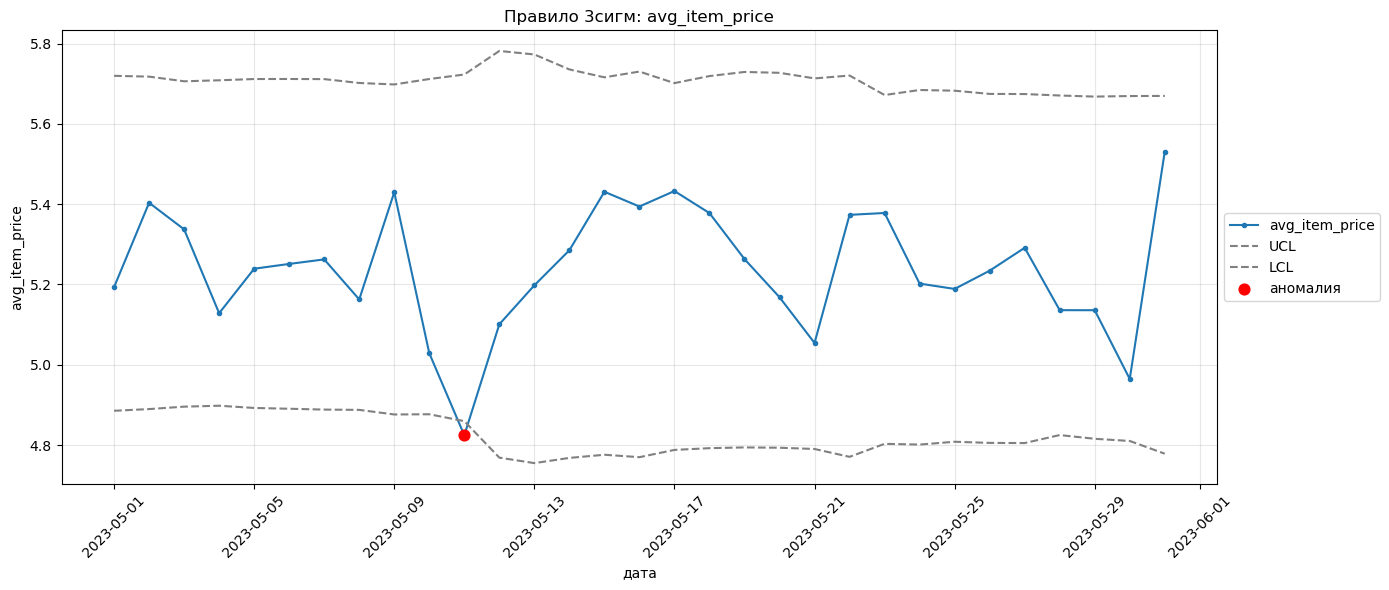

In [9]:
# Оставляю только май для визуализации
may_3sigma = df_3sigma[df_3sigma['date'].dt.month == 5].copy()

for m in metrics:
    get_3sigma_vis(may_3sigma, m)

#### 3. Дельта-ряды — 2 балла

1) Рассчитайте дельты значений текущего дня с предыдущим для каждой метрики, затем примените к полученным дельтам правило 3σ:
- gmv;
- items_sold;
- avg_item_price.

Расчет производите на всем датасете. В этом пункте вы имитируете онлайн-мониторинг, поэтому проверка проводится для каждой даты, а границы контроля рассчитываются за последние 28 дней до самой даты. 

2) Постройте графики: дельты метрики + границы контроля + выделенные аномалии.

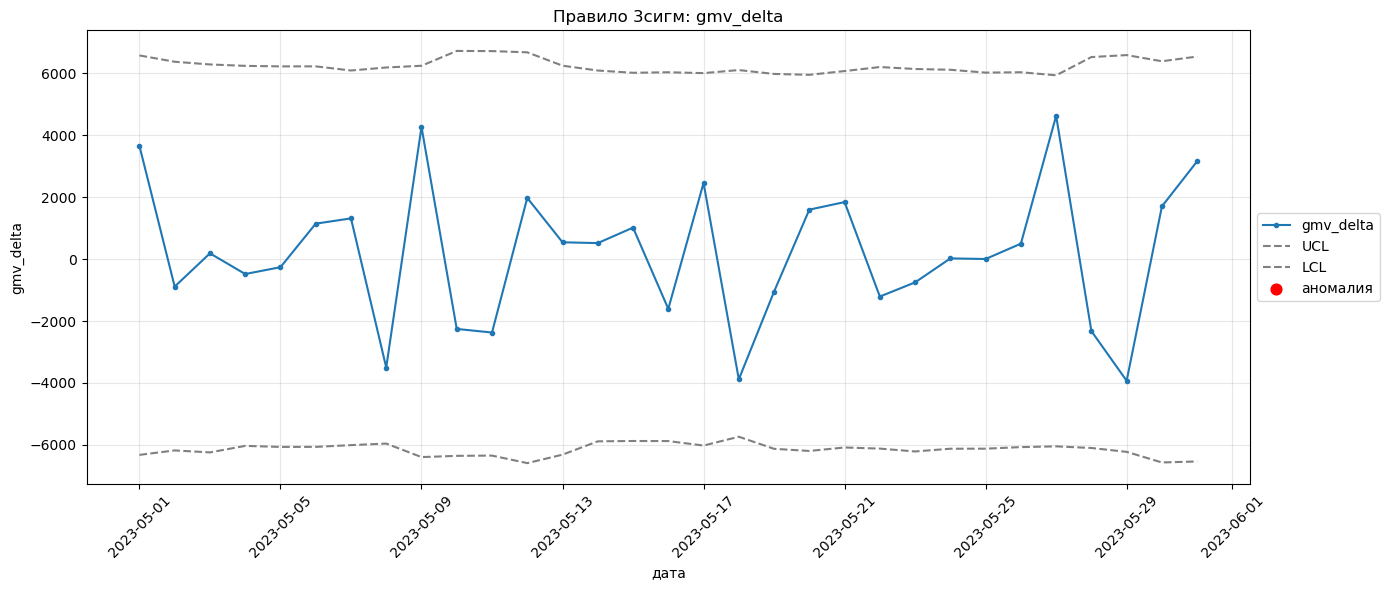

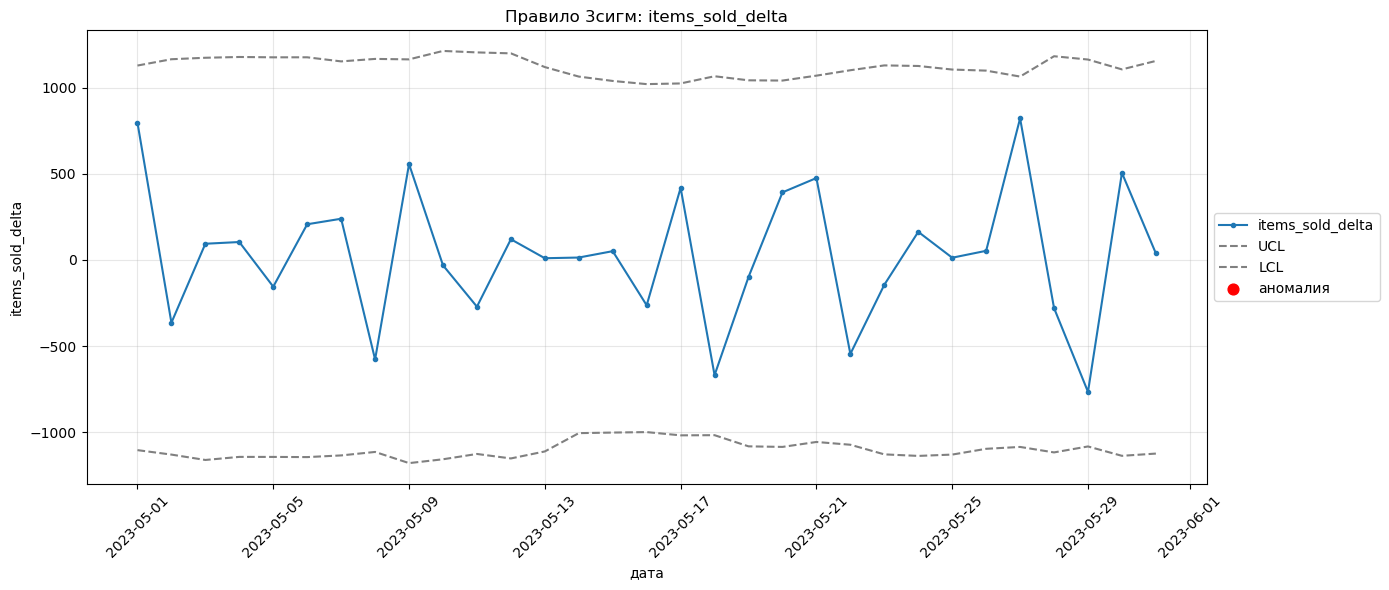

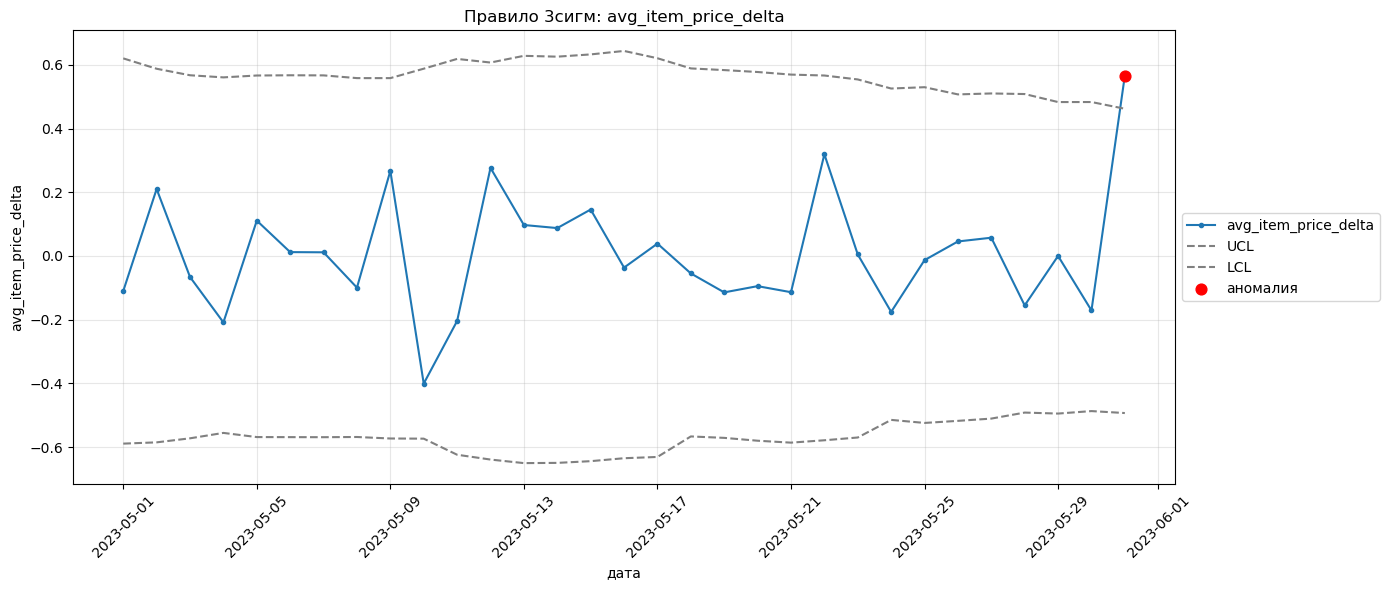

In [12]:
# your code is here
df_deltas = df.copy()
for m in metrics:
    df_deltas[f'{m}_delta'] = df_deltas[m].diff()

df_deltas_3sigma = df_deltas.copy()
for m in metrics:
    df_deltas_3sigma = get_3_sigma_cl(df_deltas_3sigma, f'{m}_delta', window=28, sigma=3)

may_deltas_3sigma = df_deltas_3sigma[df_deltas_3sigma['date'].dt.month == 5].copy()

for m in metrics:
    get_3sigma_vis(may_deltas_3sigma, f'{m}_delta')

#### 4. Generalized ESD — 2 балла

1) Реализуйте Generalized ESD. Обратите внимание, с какими данными работает метод — онлайн или батч? Учтите это в реализации.
2) Найдите аномалии для дельт каждой метрики ЗА МАЙ (используйте данные, полученные на прошлом шаге):
- gmv;
- items_sold;
- avg_item_price.
3) Сравните результаты с правилом 3σ на дельтах: разошлись ли методы?

*Советую обернуть Generalized ESD в функцию, она пригодится на следующем шаге.*

In [22]:
# your code is here
def get_generalized_esd(series, max_outliers=None, alpha=0.05):
# Если max_outliers=None, то берется floor(10% от длины)
    series = series.dropna()
    n_total = len(series)

    if max_outliers is None:
        max_outliers = math.floor(n_total * 0.1)
    max_outliers = min(max_outliers, n_total - 2)

    work = series.copy()
    outliers = []

    for _ in range(max_outliers):
        n = len(work)
        if n < 3:
            break

        mean = work.mean()
        std = work.std(ddof=1)
        if std == 0:
            break

        dev = (work - mean).abs()
        idx_max = dev.idxmax()
        R = dev.loc[idx_max]/std

        p = 1 - alpha/(2 * n)
        t_val = t.ppf(p, df=n - 2)
        lam = ((n - 1) * t_val)/math.sqrt((n - 2 + t_val ** 2) * n)

        if R > lam:
            outliers.append(idx_max)
            work = work.drop(idx_max)
        else:
            break

    return outliers

In [23]:
may_deltas = df_deltas[df_deltas['date'].dt.month == 5].copy()

In [24]:
print('Generalized ESD на дельтах за май:')
esd_delta_results = {}
for m in metrics:
    col = f'{m}_delta'
    series = may_deltas[col].dropna()
    idx = get_generalized_esd(series)
    esd_delta_results[m] = set(may_deltas.loc[idx, 'date'])

    print(f'\n{col}: {len(idx)} аномалий')
    if idx:
        print(may_deltas.loc[idx, ['date', col]])

Generalized ESD на дельтах за май:

gmv_delta: 0 аномалий

items_sold_delta: 0 аномалий

avg_item_price_delta: 1 аномалий
          date  avg_item_price_delta
150 2023-05-31              0.566188


In [25]:
print('\nСравнение 3сигм и ESD на дельтах за май:')
for m in metrics:
    col = f'{m}_delta'
    sigma_dates = set(may_deltas_3sigma.loc[may_deltas_3sigma[f'is_anomaly_{col}'], 'date'])
    esd_dates = esd_delta_results[m]

    print(f'\n{col}:')
    print(f'3сигмы: {sorted(d.date() for d in sigma_dates)}')
    print(f'ESD: {sorted(d.date() for d in esd_dates)}')
    print(f'совпали: {sorted(d.date() for d in sigma_dates & esd_dates)}')


Сравнение 3сигм и ESD на дельтах за май:

gmv_delta:
3сигмы: []
ESD: []
совпали: []

items_sold_delta:
3сигмы: []
ESD: []
совпали: []

avg_item_price_delta:
3сигмы: [datetime.date(2023, 5, 31)]
ESD: [datetime.date(2023, 5, 31)]
совпали: [datetime.date(2023, 5, 31)]


Методы сошлись для gmv и items_sold аномалий нет вообще, а для avg_item_price оба метода нашли одну и ту же аномалию (31 мая).

#### 5. STL-разложение — 2 балла

1) Для каждой метрики выполните STL-разложение с недельной сезонностью (7 дней) на данных всего датасета:
- gmv;
- items_sold;
- avg_item_price.

Используйте STL из библиотеки statsmodels (уже есть в импортах).
  
2) Для каждой метрики визуализируйте компоненты: тренд, сезонность, остатки (на всем датасете).

4) На остатках примените Generalized ESD, можете использовать функцию из прошлого шага. Это упражнение проделываем только на данных ЗА МАЙ.

5) Подумайте, для каждой ли метрики имеет смысл использовать STL, везде ли визуально присутствуют тренд и недельная сезонность?

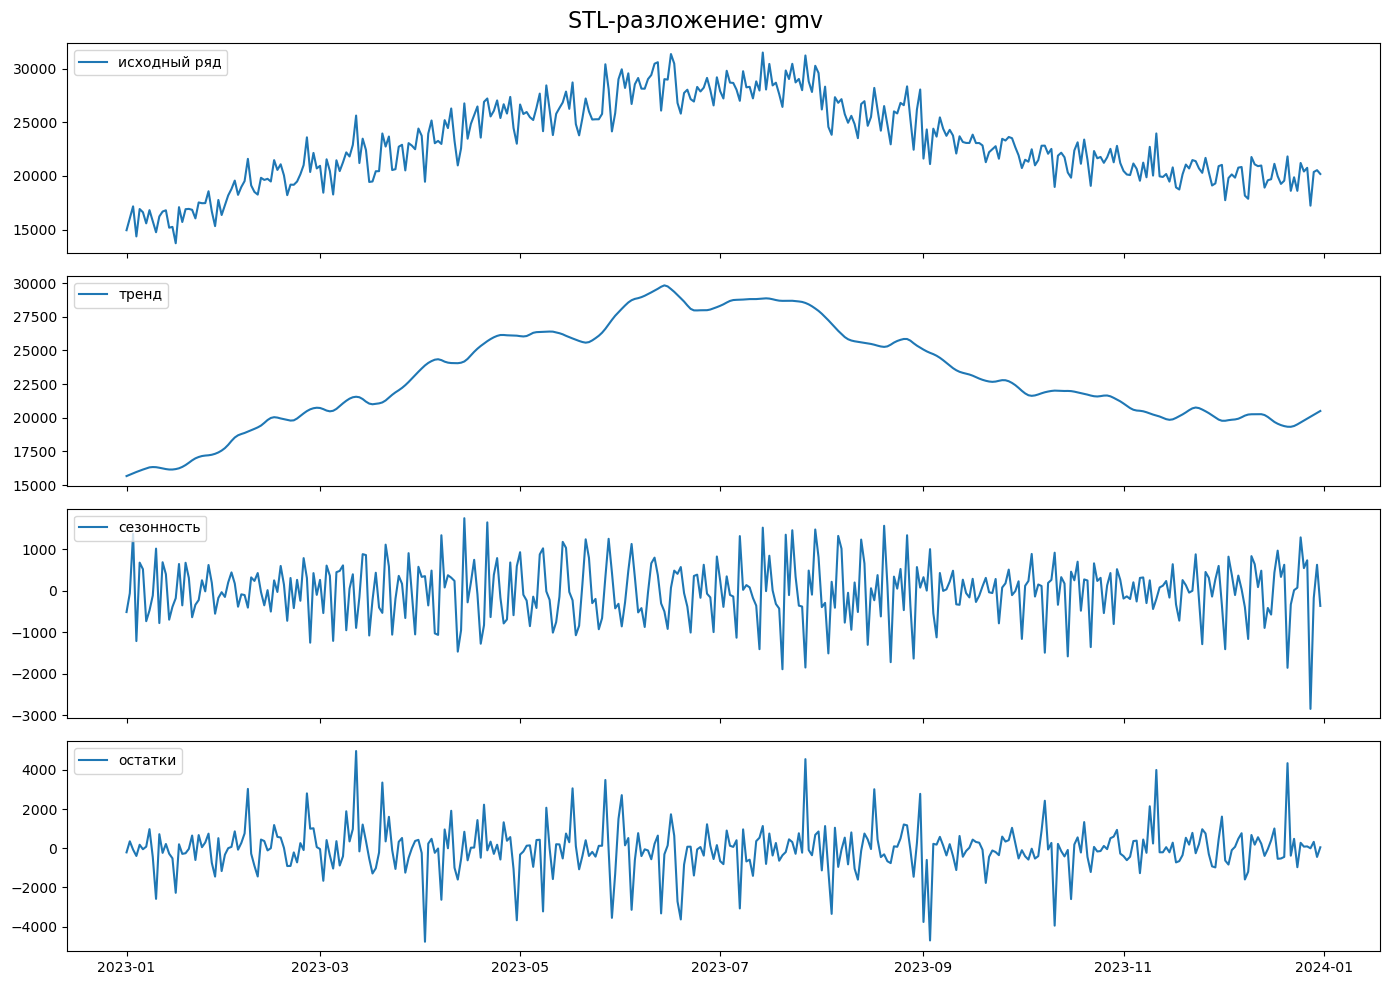

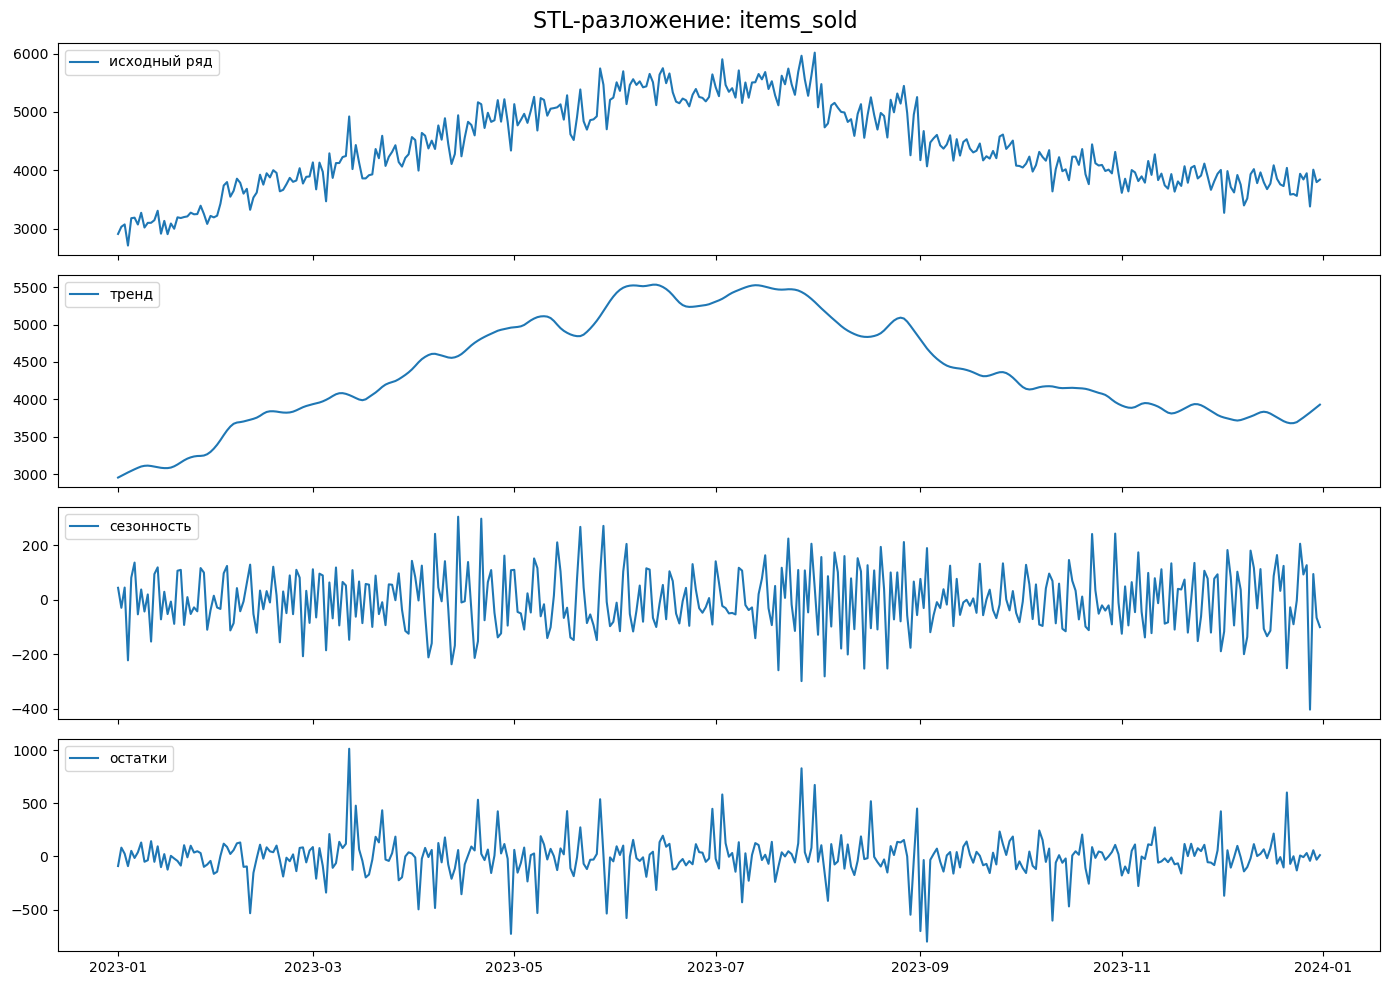

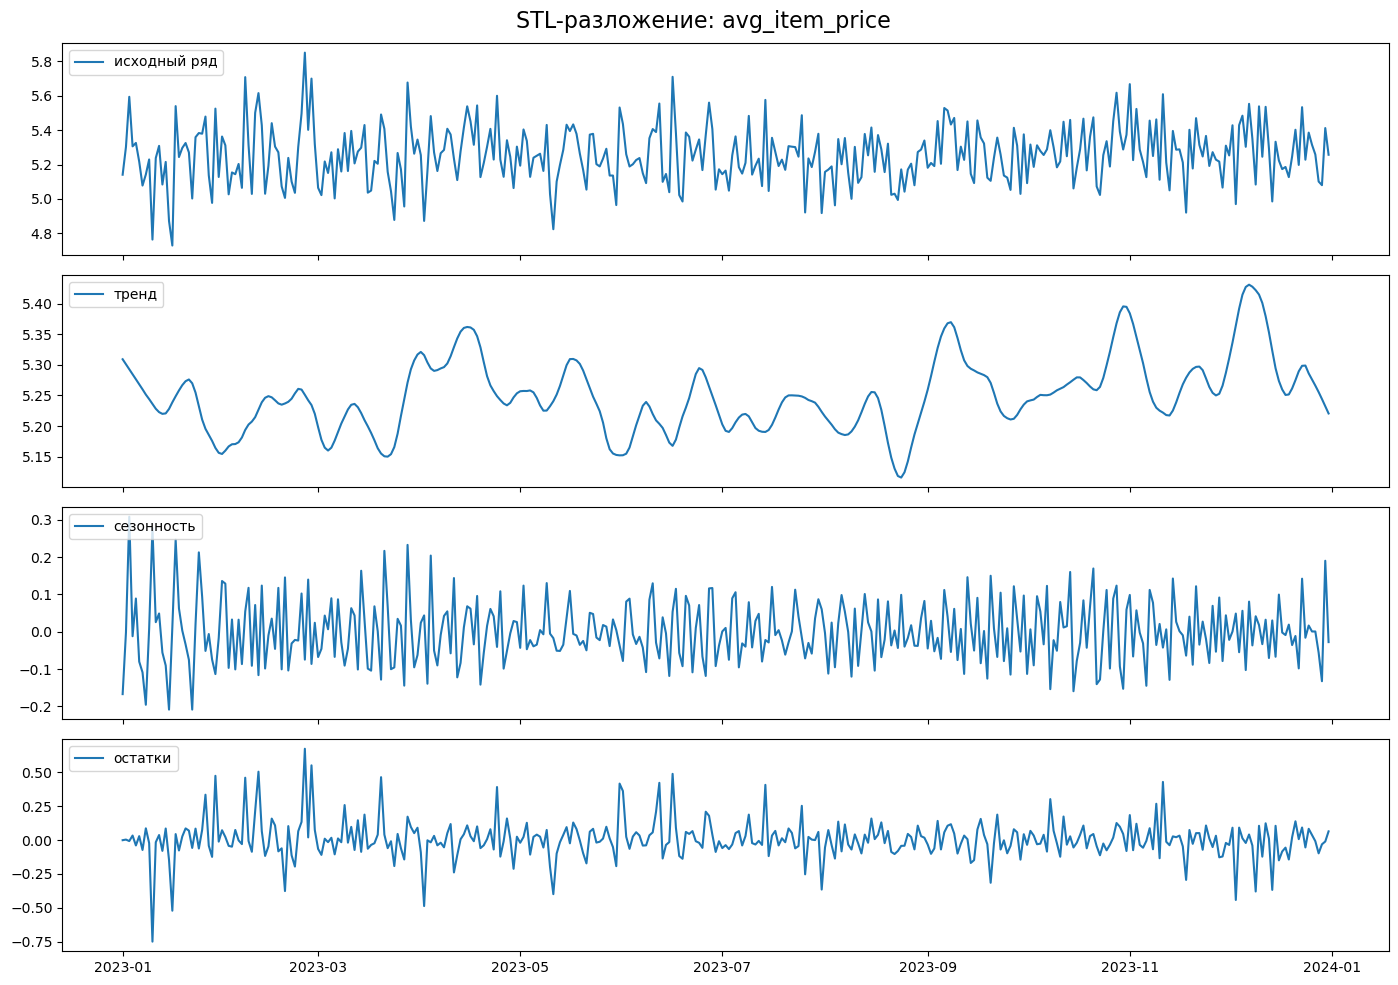

In [17]:
# your code is here
stl_fits = {}
for m in metrics:
    ts = df.set_index('date')[m]
    stl = STL(ts, period=7, robust=True)
    res = stl.fit()
    stl_fits[m] = res

    fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
    axes[0].plot(res.observed, label='исходный ряд')
    axes[0].legend(loc='upper left')
    axes[1].plot(res.trend, label='тренд')
    axes[1].legend(loc='upper left')
    axes[2].plot(res.seasonal, label='сезонность')
    axes[2].legend(loc='upper left')
    axes[3].plot(res.resid, label='остатки')
    axes[3].legend(loc='upper left')
    fig.suptitle(f'STL-разложение: {m}', fontsize=16)
    plt.tight_layout()
    plt.show()

In [18]:
# Generalized ESD на остатках STL за май
print('Generalized ESD на остатках STL за май:')
for m in metrics:
    resid = stl_fits[m].resid
    may_resid = resid[resid.index.month == 5]
    idx = get_generalized_esd(may_resid)

    print(f'\nостатки {m}: найдено {len(idx)} аномалий')
    if idx:
        print(pd.DataFrame({'date': idx, 'resid': may_resid.loc[idx].values}))

Generalized ESD на остатках STL за май:

остатки gmv: найдено 0 аномалий

остатки items_sold: найдено 0 аномалий

остатки avg_item_price: найдено 2 аномалий
        date     resid
0 2023-05-31  0.416067
1 2023-05-11 -0.399040


Stl-разложение следует применять к рядам, которые имеют выраженный тренд, сезонность, чтобы фильтровать и не ловить ложные аномалии (по визуализации - это gmv, items_sold). Если нет явного тренда (это avg_item_price), то не надо

#### 6. EWMA — 2 балла

1) Реализуйте метод EWMA для каждой метрики:
- gmv;
- items_sold;
- avg_item_price.

Сглаженная статистика считается рекуррентно с параметром $\lambda = 0.2$:

$$
z_t = \lambda x_t + (1-\lambda)\, z_{t-1}, \qquad z_0 = x_0,
$$

где $x_t$ — исходное дневное значение метрики. В pandas это делает [встроенная функция экспоненциального сглаживания](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.ewm.html) — обратите внимание на параметр `adjust=False`, именно он дает рекуррентную форму выше.

Контрольные границы задаются как

$$
\mu_t \pm L\,\sigma_t \sqrt{\frac{\lambda}{2-\lambda}}, \qquad L = 3.
$$

Здесь $\mu_t$ и $\sigma_t$ — среднее и стандартное отклонение **исходного ряда $x_t$**, а не сглаженного $z_t$, посчитанные на скользящем окне 28 дней. Множитель $\sqrt{\lambda/(2-\lambda)}$ — асимптотическое приближение отношения дисперсии сглаженной статистики к дисперсии сырых наблюдений: он уже учитывает, что $z_t$ колеблется меньше, чем $x_t$, поэтому подставлять в формулу разброс самого $z_t$ нельзя — сжатие применится дважды, и коридор получится слишком узким.

Окно для $\mu_t$ и $\sigma_t$ должно заканчиваться на предыдущем дне (`.rolling(28).mean().shift(1)`), иначе текущее наблюдение попадёт в собственную оценку разброса и аномалия спрячет сама себя.

2) Постройте графики: сглаженная метрика + границы контроля + выделенные аномалии.
3) Напишите, какой из подходов вам больше всего понравился для онлайн-мониторинга, а какой — для ретроспективного анализа, и почему. Тут нет правильного ответа :)

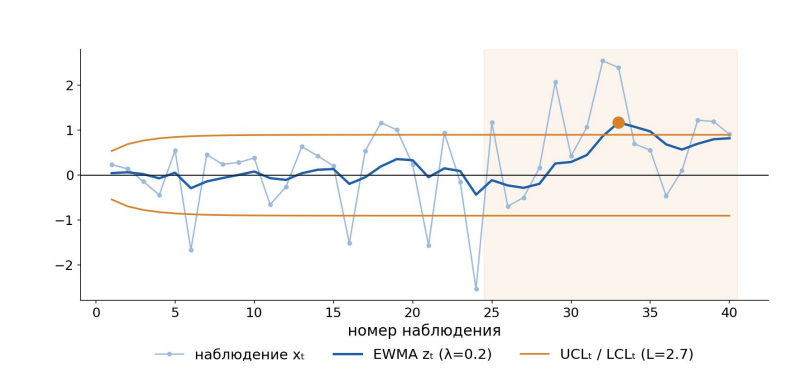

In [19]:
# your code is here
def get_ewma_cl(df, metric, lam=0.2, L=3, window=28):
    df = df.copy()
    df[f'{metric}_ewma'] = df[metric].ewm(alpha=lam, adjust=False).mean()

    shifted = df[metric].shift(1)
    df[f'{metric}_mean'] = shifted.rolling(window=window, min_periods=window).mean()
    df[f'{metric}_ssd'] = shifted.rolling(window=window, min_periods=window).std(ddof=1)

    k = L * np.sqrt(lam / (2 - lam))
    df[f'{metric}_ucl'] = df[f'{metric}_mean'] + k*df[f'{metric}_ssd']
    df[f'{metric}_lcl'] = df[f'{metric}_mean'] - k*df[f'{metric}_ssd']

    df[f'is_anomaly_{metric}'] = (
        (df[f'{metric}_ewma'] > df[f'{metric}_ucl']) |
        (df[f'{metric}_ewma'] < df[f'{metric}_lcl'])
    )
    return df

In [20]:
def get_ewma_vis(df, metric, date_col='date'):
    
    plt.figure(figsize=(14, 6))
    plt.plot(df[date_col], df[metric], alpha=0.4, marker='o', markersize=3, label=f'{metric} (сырой)')
    plt.plot(df[date_col], df[f'{metric}_ewma'], color='blue', linewidth=2, label=f'{metric} EWMA')
    plt.plot(df[date_col], df[f'{metric}_ucl'], linestyle='--', color='grey', label='UCL')
    plt.plot(df[date_col], df[f'{metric}_lcl'], linestyle='--', color='grey', label='LCL')

    anom = df[df[f'is_anomaly_{metric}']]
    plt.scatter(anom[date_col], anom[f'{metric}_ewma'], color='red', s=60, zorder=5, label='аномалия')

    plt.title(f'EWMA: {metric}')
    plt.xlabel('дата')
    plt.ylabel(metric)
    plt.xticks(rotation=45)
    plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

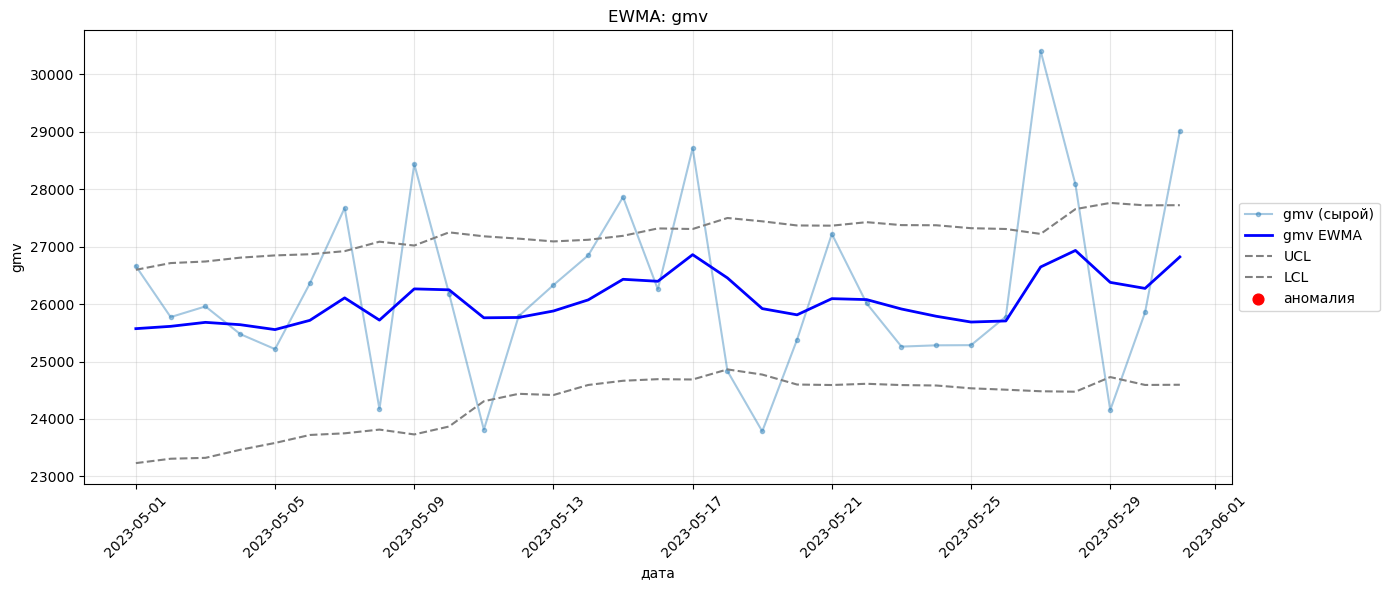

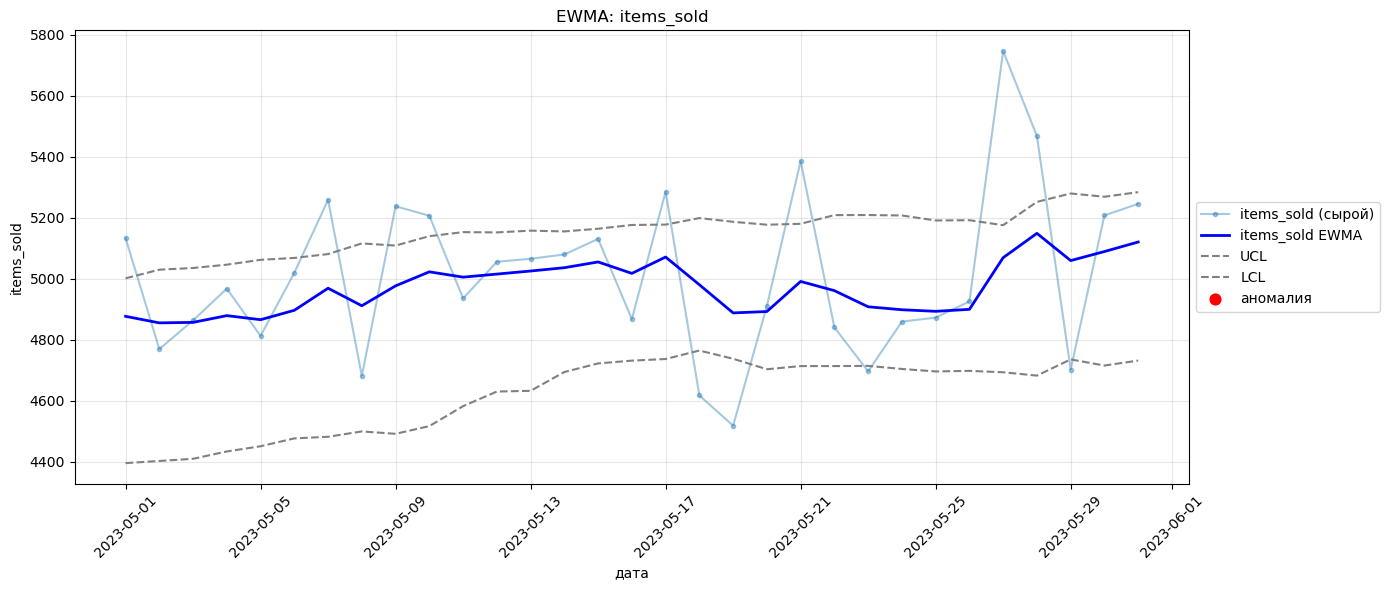

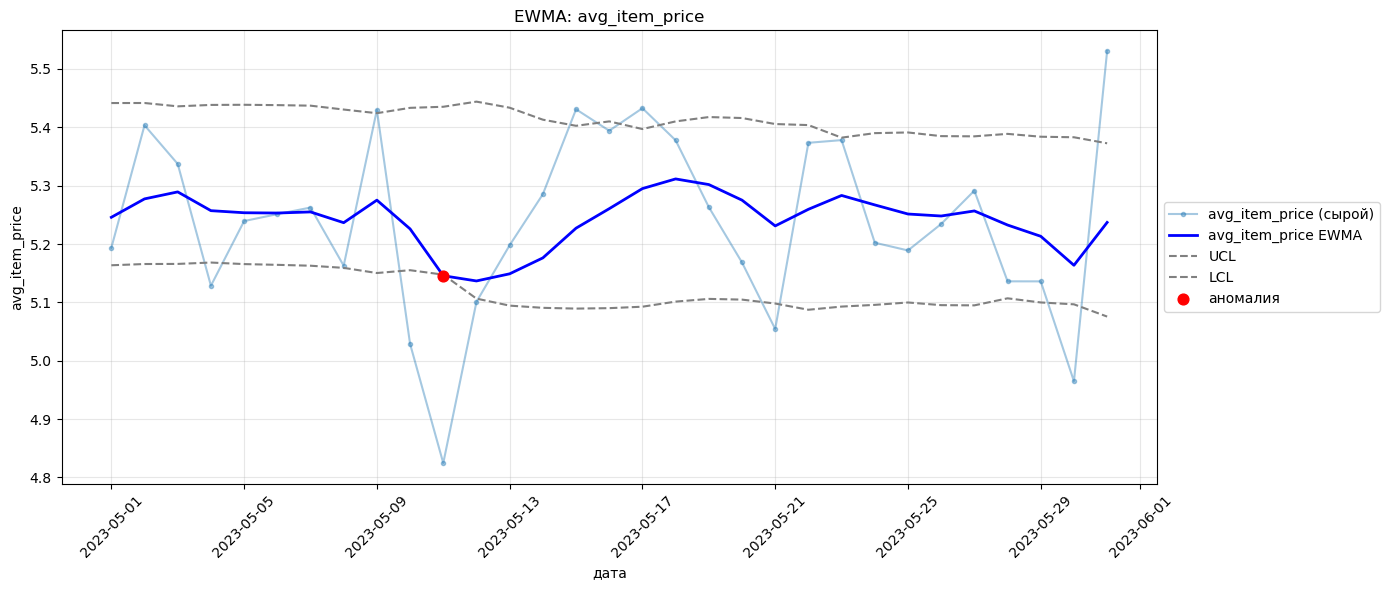

In [21]:
df_ewma = df.copy()
for m in metrics:
    df_ewma = get_ewma_cl(df_ewma, m, lam=0.2, L=3, window=28)

may_ewma = df_ewma[df_ewma['date'].dt.month == 5].copy()
for m in metrics:
    get_ewma_vis(may_ewma, m)

Мне больше понравился ewma для онлайн-мониторинга, потому что не надо хранить всю историю + хорошо сглаживает шум. Также он обновляется по 1 дню

Для ретроперспективного анализа лучше STL + Generalized ESD: убирает тренд, сезонность (что нужно для gmv и items_sold), esd же по остаткам отделяет реальные аномалии от шума